# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** [Streamlit app](https://dashboards-movielens.streamlit.app/)

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [ ]:
%pip install seaborn

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [4]:
# Your data checks here
df.shape[0]

100000

In [5]:
df.dtypes


user_id          int64
movie_id         int64
rating           int64
timestamp          str
age              int64
gender             str
occupation         str
zip_code           str
title              str
year           float64
decade         float64
genres             str
rating_year      int64
dtype: object

In [6]:
raw_zipcodes = df[pd.to_numeric(df['zip_code'], errors='coerce').isna()]
print(len(raw_zipcodes))
print(raw_zipcodes['zip_code'].value_counts())
df['zip_code'] = pd.to_numeric(df['zip_code'], errors='coerce').astype('Int64')

2086
zip_code
E2A4H    386
N2L5N    317
V3N4P    316
Y1A6B    183
T8H1N    174
N4T1A    138
L1V3W    124
E2E3R     74
L9G2B     69
V0R2H     67
V5A2B     57
R3T5K     47
K7L5J     37
V0R2M     26
M4J2K     25
M7A1A     24
V1G4L     22
Name: count, dtype: int64


In [7]:
df.isna().sum()

user_id           0
movie_id          0
rating            0
timestamp         0
age               0
gender            0
occupation        0
zip_code       2086
title             0
year             30
decade           30
genres            0
rating_year       0
dtype: int64

In [8]:
print(df.duplicated().sum())

0


In [9]:
num = df.select_dtypes(include='number')
ranges = num.max() - num.min()
print(ranges)

user_id          942.0
movie_id        1681.0
rating             4.0
age               66.0
zip_code       99835.0
year              76.0
decade            70.0
rating_year        1.0
dtype: Float64


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_
The zipcode is str and that needs to be changed to int. 
There are no duplicates. 
The missing values (NaN) are only in year and decade, which can be kept as is for now.

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Each movie will have a genre column, this can be a horizatal chart. If movies have multiple genres, then it will count once towards each genre.
- Why: A horizontal bar can be the best can the genre won't be much and it won't look clustered

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: For each genre, average all ratings given to movies in that genre. If a movie has multiple genres, its ratings contribute to each of them This can be a horizontal bar chart and include the number of ratings for context.
- Why: 

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: The movies with missing year can be not included in this chart since its for ratings over time. Every year will not be backend with the same amount of movies, some years can have more movies released. The best chart will be line chart
- Why:

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movie’s rating is the mean of its user ratings. If multiple movies tie, all the candidates can be included.
- Why: Vertical bot plot 

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

[Text(0, 0.5, 'Genre'), Text(0.5, 0, 'Unique movies')]

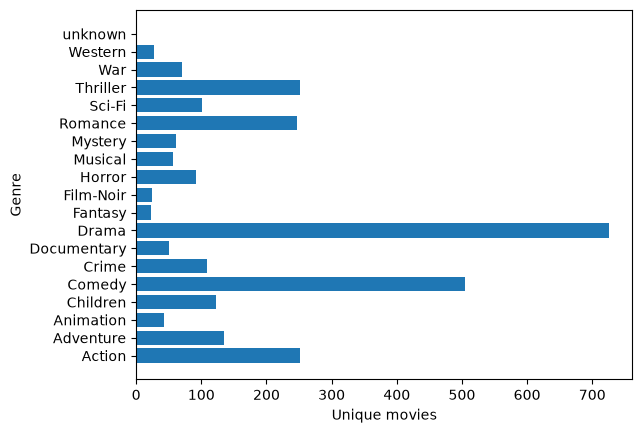

In [10]:
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
counts = genre_df.groupby("genre")["movie_id"].nunique()

fig, ax = plt.subplots()
ax.barh(counts.index, counts.values)
ax.set(ylabel="Genre", xlabel="Unique movies")

**✏️ My answer (with numbers):** _(Which genres dominate, by how much, and what exactly did you count?)_

The drama genre is the highest with 700 unique movies and the comedy is the second highest genre with around 500 unique movies. 

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

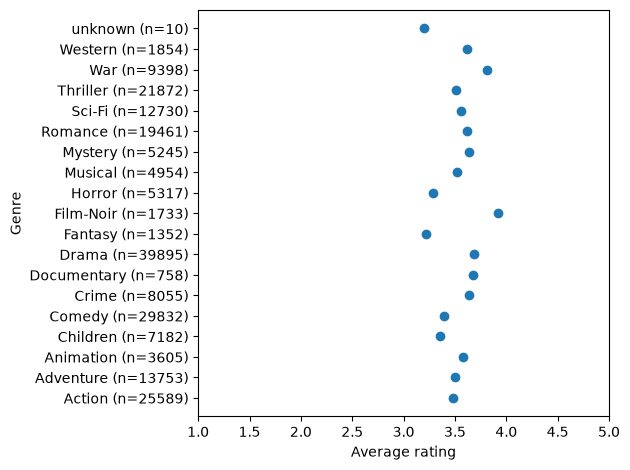

In [11]:
# Q2: your code here
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')

genre_stats = genre_df.groupby("genre")["rating"].agg(["mean", "count"])

labels=[]
for genre, count in zip(genre_stats.index, genre_stats["count"]):
    labels.append(f"{genre} (n={count})")

fig, ax = plt.subplots()

ax.scatter(genre_stats["mean"], labels)  
ax.set(xlim=(1, 5), xlabel="Average rating", ylabel="Genre")

plt.tight_layout()
plt.show()

In [17]:
lowest_genre = genre_stats["mean"].idxmin()
lowest = genre_df[genre_df["genre"] == lowest_genre]

n = lowest["rating"].count()
movie_count = lowest["movie_id"].nunique()

# Calculate mean and 95% interval
mean = lowest["rating"].mean()
std = lowest["rating"].std()
margin = 1.96 * std / n**0.5

print("Lowest-rated genre:", lowest_genre)
print("Average rating:", mean)
print("Number of ratings:", n)
print("Number of distinct movies:", movie_count)
print("Rough 95% interval:", (mean - margin).round(4), (mean + margin).round(4))

Lowest-rated genre: unknown
Average rating: 3.2
Number of ratings: 10
Number of distinct movies: 2
Rough 95% interval: 2.384 4.016


**✏️ My answer (with numbers):** _(Top and bottom genres, their averages, and how much data each one rests on.)_
The top genre is film noir with n=1733 and the average rating is around 4. The botton genre is unknown with n=10 and the average of around 3. 

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

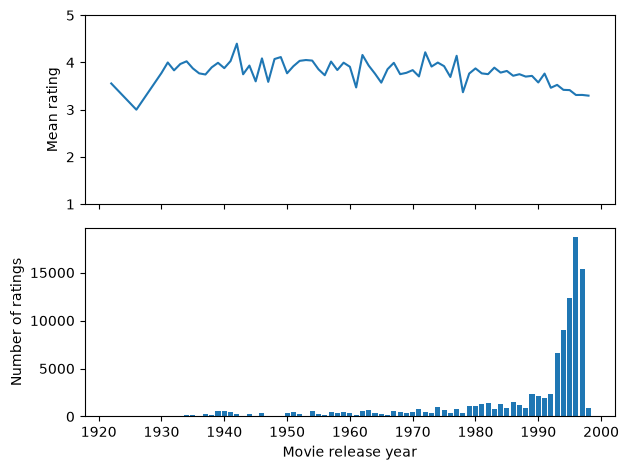

In [13]:
# Q3: your code here
yearly = df.dropna(subset=["year"]).groupby("year")["rating"].agg(["mean", "count"])  
fig, (rating_ax, count_ax) = plt.subplots(2, 1, sharex=True)  

rating_ax.plot(yearly.index, yearly["mean"])  
rating_ax.set_ylabel("Mean rating")  
rating_ax.set_ylim(1, 5) 

count_ax.bar(yearly.index, yearly["count"])  
count_ax.set_xlabel("Movie release year")  
count_ax.set_ylabel("Number of ratings")  
fig.tight_layout()  
plt.show()  


**✏️ My answer (with numbers):** _(What's the trend? Is it equally believable across the whole timeline?)_
THe ratings have flatuated for all years but the early years, its not very belivable since the rating is based on very small number of ratings compared to for example, 1990s

In [20]:
print(df['rating_year'].unique())

[1997 1998]


## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

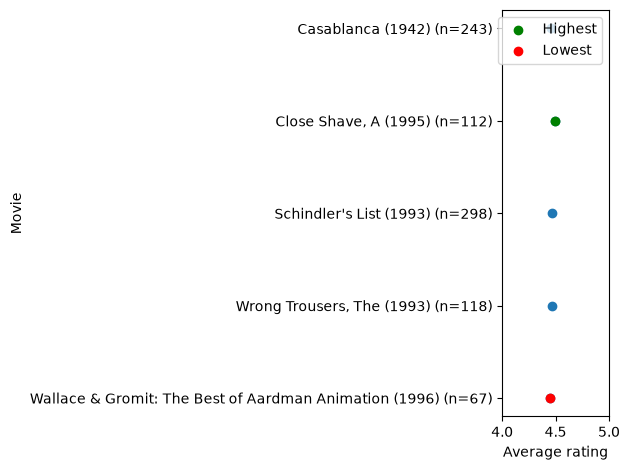

In [14]:
movie_stats = df.groupby("movie_id").agg( title=("title", "first"), mean=("rating", "mean"),
    count=("rating", "count"),
)

eligible = movie_stats[movie_stats["count"] >= 50]

if len(eligible) > 5:
    cutoff = eligible["mean"].nlargest(5).min()
    top = eligible[eligible["mean"] >= cutoff]  # Keep all movies tied at fifth place.
else:
    top = eligible

labels = []
for title, count in zip(top["title"], top["count"]):
    labels.append(f"{title} (n={count})")

top = top.copy()
top["label"] = labels  

fig, ax = plt.subplots()
ax.scatter(top["mean"], top["label"], color="C0")  # Keep all points in the default blue.
highest = top[top["mean"] == top["mean"].max()]
lowest = top[top["mean"] == top["mean"].min()]
ax.scatter(highest["mean"], highest["label"], color="green", label="Highest")
ax.scatter(lowest["mean"], lowest["label"], color="red", label="Lowest")
ax.set(xlim=(4, 5), xlabel="Average rating", ylabel="Movie")
ax.legend()

fig.tight_layout()
plt.show()

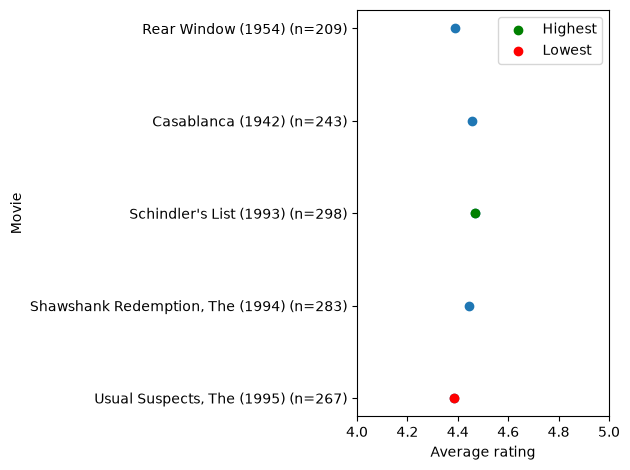

In [15]:
movie_stats = df.groupby("movie_id").agg( title=("title", "first"), mean=("rating", "mean"),
    count=("rating", "count"),
)

eligible = movie_stats[movie_stats["count"] >= 150]

if len(eligible) > 5:
    cutoff = eligible["mean"].nlargest(5).min()
    top = eligible[eligible["mean"] >= cutoff]  # Keep all movies tied at fifth place.
else:
    top = eligible

labels = []
for title, count in zip(top["title"], top["count"]):
    labels.append(f"{title} (n={count})")

top = top.copy()
top["label"] = labels  

fig, ax = plt.subplots()
ax.scatter(top["mean"], top["label"], color="C0")  # Keep all points in the default blue.
highest = top[top["mean"] == top["mean"].max()]
lowest = top[top["mean"] == top["mean"].min()]
ax.scatter(highest["mean"], highest["label"], color="green", label="Highest")
ax.scatter(lowest["mean"], lowest["label"], color="red", label="Lowest")
ax.set(xlim=(4, 5), xlabel="Average rating", ylabel="Movie")
ax.legend()

fig.tight_layout()
plt.show()

**✏️ My answer (with numbers):** _(Both top-5 lists. Which movies dropped out or moved in when the floor went up, and what does that say about small samples?)_
when the floor went to 150, the highest rating movie changed from close shave to schindler's list. The lowest rating changed from wallace and gomit to usual suspects. It shows small samples are unreliable

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

Paste 2 prompts that shaped it (from your build log, or from your AI chat history if you didn't keep a log; don't invent any). For each one: what did you ask, what did the AI give you first, and what did you change or accept without checking?

**Prompt 1**
- What I asked:  MovieLens movie_ratings.csv. Four charts (genre distribution, genre mean ratings, mean rating by release year, top 5 movies with rating-count floors of 50 then 150).
- AI's first attempt: 
    Unique-movie genre counts for Q1.
    Rating-level means for Q2.
    Use year (release), not rating_year, for Q3.
    One min-ratings slider for Q4 instead of two static charts.
- What I changed (or accepted without checking): Pie chart was recommened for Q1 and it was changed to horizontal bar chart

**Prompt 2**
- What I asked: Implement the attached plan
- AI's first attempt:
    Single app.py: cached load_ratings / explode_genres / unique movies.
    Sidebar: genre multi-select (all selected), release-year slider (Q3), min-ratings slider default 50 (Q4).
    Four Altair charts + a short 50-vs-150 caption under Q4.
- What I changed (or accepted without checking): Accepted the dashboards

## 3.2 Compare the answers

Read the answer off your dashboard for each question and put it next to yours.

**Q1**
- Dashboard says: It counts unique movies and a movie listed under multiple genres is counted multiple times. 
- I say: The same idea as well.
- Same? (yes / partly / no): yes
- If different, why?

**Q2**
- Dashboard says: Uses a horizontal bar chart
- I say: It would be better to use a scatter plot
- Same? (yes / partly / no): no
- If different, why? The ratings are around 3 to 4, the horizontal chart is not showing any valuable information. The count is also missing.

**Q3**
- Dashboard says: Uses a line plot to find ratings from movie years
- I say: the count is missing
- Same? (yes / partly / no): partly
- If different, why? The count is required for understanding the ratings

**Q4**
- Dashboard says: uses a horizontal bar chart to find the top 5 movies with more than 50 ratings
- I say: The scatter plot will be better as the rats are usually around 4 - 5, a very small x-axis scale.
- Same? (yes / partly / no): no
- If different, why? since the x-axis scale is small, using a scatter plot will be better.

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**✏️ Pick two questions and explain what's going on** (2 to 3 sentences each). Track down the *actual cause*: read your dashboard's code, or re-run it with one change. "The AI did it differently" is not an explanation. If the answers match, say why you now trust them.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used: horizontal bar chart
- Chart I used: horizontal bar chart
- Which communicates the answer better, and why? Both is the same in this case

**Q2**
- Chart the dashboard used: horizontal bar chart
- Chart I used: horizontal dot plot
- Which communicates the answer better, and why? The dot plot since it highlights the difference between the ratings better when the scale is small

**Q3**
- Chart the dashboard used: Line plot
- Chart I used: Line plot and bar chart
- Which communicates the answer better, and why? Mine since it uses a line plot for the average ratings but also has the bar chart with the same x-axis to show the counts for each rating

**Q4**
- Chart the dashboard used: a horizontal bar chart
- Chart I used: horizontal dot plot
- Which communicates the answer better, and why? Mine since it shows the highest and lowest using difference colors and the its readable with a small scale.

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

In [24]:
user_counts = df.groupby("user_id").size()
print(user_counts.head(5))

min_users_count = user_counts.min()
print(min_users_count)
max_users_count = user_counts.max()
print(max_users_count)

min_user_id = user_counts.idxmin()
max_user_id = user_counts.idxmax()

min_years = df[df["user_id"] == min_user_id]["rating_year"]
max_years = df[df["user_id"] == max_user_id]["rating_year"]

print("Minimum-count user:", min_user_id, "\n", "rating years:", min_years.tolist(), "\n")
print("Maximum-count user:", max_user_id, "\n", "rating years:", max_years.tolist(), "\n")

user_id
1    272
2     62
3     54
4     24
5    175
dtype: int64
20
737
Minimum-count user: 19 
 rating years: [1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998] 

Maximum-count user: 405 
 rating years: [1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998, 1998

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_
1. The users in the dataset rated min of 19 movies and max 474 movies. There doesn't seem to be people who only submitted 1 review. The Q2 is the genre statisfaction for each genre and the ratings of each. If users submited many reviews for a specific genre, then that genre is overrepresented in the dataset causing sampling bias. 
2.
3.


## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better): sampling bias and the calculations of using count along with the ratings. Understand the kind of charts for the kind of data.

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right): It knows what kind of charts to use for large samples.

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when? The AI would handle writing the code but I would ask it to include comments and prompt it to explain the key ideas. I have to ultimately drive it.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week